# 21 · Análisis exploratorio: el locro de las configuraciones guardadas

**Etapa 26 del plan.** Desde el `17` hubo tres empates a favor seguidos: las combinaciones de Visa y Master (+0,58 M), las 400 hojas (+0,60 M) y los cambios relativos de Tomás (+0,64 M). Cada configuración ve a los clientes con columnas distintas. Un promedio de sus predicciones (el "locro" de la competencia 1) puede sumar lo que cada una tiene de propio.

**Pregunta:** ¿un locro de configuraciones gana más dinero que `ACH_4_P3`, con la misma cantidad de modelos?

**La receta** (decisión 1 de la ficha): las 4 variantes de `ACH_4` con peso 3 y todas las filas. Solo cambian las columnas.

| Configuración | Notebook | Qué agrega a `ACH_4` |
|---|---|---|
| `ACH_4_P3` | `15` | Nada: es la vigente |
| `ACH_4_MV_P3` | `17` | 43 combinaciones de Visa y Master |
| `ACH_4_MVH_P3` | `17` | Las combinaciones y su historia |
| `ACH_4_R_P3` | `20` | Los cambios relativos de Tomás (258 columnas) |

**Cómo se promedia** (decisión 2): cada modelo ordena a los clientes del mes, y se promedia el puesto de cada cliente (su percentil dentro del mes). Los envíos se cortan por cantidad, así que solo importa el orden.

**Con la misma cantidad de modelos** (decisión 3). Para cada semilla *s* se comparan:
- **el locro:** las 4 configuraciones con la semilla *s* (4 modelos);
- **el semillerío de `ACH_4_P3`:** las otras 4 semillas (4 modelos).

Si el locro gana, no es por tener más modelos: es por la variedad de columnas.

**No entrena modelos.** Lee las predicciones del banco temporal que guardaron el `15`, el `17`, el `18` y el `20` (201906 a 201910, 5 semillas).

**Todo lo de este notebook es exploratorio.** No cambia el resultado de la regla pre-registrada. No carga 201911 ni 201912. **No escribe en `exp/` ni en los `resultados/03_*` a `20_*`:** solo los lee.

Ficha: `fichas/etapa_26_locro.md` (en el laboratorio).

## 1. Parámetros

In [1]:
from pathlib import Path
import hashlib
import resource
import sys
import time

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy.stats import rankdata

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP = Path('../exp')                                # solo se lee: exp/15, exp/17, exp/18 y exp/20
FIGURAS = RESULTADOS / 'figuras'

MES_TOPE = 201910                                   # nada posterior entra a este notebook
MESES_CLASE = [201903, 201904, 201905, 201906, 201907, 201908, 201909, 201910]
MESES_EVALUADOS = [201906, 201907, 201908, 201909, 201910]

INGREDIENTES = {                                    # configuración: notebook que guardó sus predicciones
    'AC': '15', 'ACH': '15', 'ACH_4': '15', 'ACH_4_P2': '15', 'ACH_4_P3': '15',
    'ACH_4_MV_P3': '17', 'ACH_4_MVH_P3': '17', 'ACH_4_R_P3': '20',
    'ACH_4_P3_U10': '18', 'ACH_4_P1_U10': '18', 'ACH_4_P3_U10_H': '18',
}
REFERENCIA = 'ACH_4_P3'
RECETA = ['ACH_4_P3', 'ACH_4_MV_P3', 'ACH_4_MVH_P3', 'ACH_4_R_P3']   # decisión 1 (a) de la ficha
OLLA = list(INGREDIENTES)                           # "todo a la olla": solo para informar
UMBRAL = 1.0                                        # M por mes, fijado en la ficha
ENVIOS = [2_000, 3_000, 4_000, 5_000, 6_000, 8_000, 10_000]   # curva por cantidad de envíos, solo para informar
N_PARECIDO = 4_000                                  # clientes en común entre los primeros N puestos

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 5
N_BOOTSTRAP = 2_000
BANDA = (3_000, 6_000)                              # ambos incluidos
GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
LARGO_CURVA = 15_000
# -----------------------------------------------------------------------------

FIGURAS.mkdir(parents=True, exist_ok=True)
ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_CLASE = (1_037_551, 5_042)                 # filas y BAJA+2 de 201903 a 201910
ESPERADO_PREDICCIONES = 275                         # 11 configuraciones × 5 meses × 5 semillas


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]


def huella_archivos():
    """Control 7: huella de las salidas anteriores, para comprobar que no cambian."""
    archivos = [*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[0123456789]_*'), *RESULTADOS.glob('20_*')]
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest() for p in sorted(archivos)}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 60


## 2. La clase

Del dataset se leen solo el número de cliente, el mes y la clase. Las filas quedan en el mismo orden que usaron los notebooks que guardaron las predicciones: por mes y por número de cliente.

**Control 1:** filas y `BAJA+2` de 201903 a 201910. **Control 2:** nada posterior a 201910 entra al notebook.

In [2]:
def curva(puntaje, es_b2):
    """Ganancia acumulada al enviar a los clientes en orden de puntaje, de mayor a menor."""
    orden = np.argsort(-puntaje, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select numero_de_cliente, foto_mes, clase_ternaria from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {MES_TOPE}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].max() == MES_TOPE                                 # control 2
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES
en_clase = base['foto_mes'].isin(MESES_CLASE)
assert (int(en_clase.sum()), int((base.loc[en_clase, 'clase_ternaria'] == 'BAJA+2').sum())) == ESPERADO_CLASE   # control 1

base = base[base['foto_mes'].isin(MESES_EVALUADOS)]
FOTO_MES = base['foto_mes'].to_numpy()
CLIENTES, POS_CLIENTE = np.unique(base['numero_de_cliente'].to_numpy(), return_inverse=True)
es_mes = {m: FOTO_MES == m for m in MESES_EVALUADOS}
Y = {m: (base['clase_ternaria'].to_numpy() == 'BAJA+2')[es_mes[m]] for m in MESES_EVALUADOS}
POS = {m: POS_CLIENTE[es_mes[m]] for m in MESES_EVALUADOS}
del base
print(f'Clase cargada en {time.time() - t0:.0f} s · controles 1 y 2 OK')

Clase cargada en 0 s · controles 1 y 2 OK


## 3. Las predicciones guardadas

**Control 3:** las 275 predicciones (11 configuraciones × 5 meses × 5 semillas) están, cada una del largo de su mes y sin faltantes.

**Control 4:** la ganancia en la banda de cada modelo suelto coincide con la que guardó su notebook (`15_meses.csv`, `17_meses.csv`, `18_meses.csv` y `20_meses.csv`). Si coincide, las predicciones están en el mismo orden que la clase.

In [3]:
t0 = time.time()
P = {}
for c, e in INGREDIENTES.items():
    for m in MESES_EVALUADOS:
        v = np.stack([np.load(EXP / e / 'pred' / c / str(m) / f'{s}.npy') for s in SEMILLAS]).astype(np.float64)
        assert v.shape == (N_SEMILLAS, es_mes[m].sum()) and np.isfinite(v).all(), (c, m)   # control 3
        P[(c, m)] = v
assert len(P) * N_SEMILLAS == ESPERADO_PREDICCIONES

guardado = pd.concat([pd.read_csv(RESULTADOS / f'{e}_meses.csv') for e in sorted(set(INGREDIENTES.values()))])
assert (guardado.groupby(['config', 'semilla', 'foto_mes'])['ganancia_banda_M'].agg(lambda s: s.max() - s.min()) < 1e-9).all()
guardado = guardado.drop_duplicates(['config', 'semilla', 'foto_mes']).set_index(['config', 'semilla', 'foto_mes'])['ganancia_banda_M']
dif_max = max(abs(banda(curva(P[(c, m)][i], Y[m])) / 1e6 - guardado[(c, s, m)])
              for c, m in P for i, s in enumerate(SEMILLAS))
assert dif_max < 1e-4, dif_max                                                               # control 4
print(f'Controles 3 y 4 OK en {time.time() - t0:.0f} s: {ESPERADO_PREDICCIONES} predicciones, '
      f'diferencia máxima con lo guardado {dif_max:.1e} M · memoria máxima {memoria_gb()} GB')

Controles 3 y 4 OK en 3 s: 275 predicciones, diferencia máxima con lo guardado 5.0e-05 M · memoria máxima 0.7 GB


## 4. Puestos, locros y semillerios

**El puesto** de un cliente en un modelo es su percentil dentro del mes: 1 para el de mayor probabilidad, cerca de 0 para el de menor. Los empates reciben el puesto promedio.

**Control 5:** el locro de una sola configuración da el mismo orden que su probabilidad (la misma curva de ganancia), para las 11 configuraciones, los 5 meses y las 5 semillas.

**Control 6:** en 201908, con la primera semilla, el locro de la receta calculado a mano (contando, para cada cliente, cuántos tienen menos probabilidad) coincide en 300 clientes al azar.

In [4]:
t0 = time.time()
PUESTO = {k: np.stack([rankdata(p, method='average') / p.size for p in v]) for k, v in P.items()}


def locro(configs, m, i):
    """Promedio de los puestos de las configuraciones, todas con la semilla i."""
    return np.mean([PUESTO[(c, m)][i] for c in configs], axis=0)


def semillerio(config, m, semillas):
    """Promedio de los puestos de una configuración con varias semillas."""
    return PUESTO[(config, m)][list(semillas)].mean(axis=0)


otras = lambda i: [j for j in range(N_SEMILLAS) if j != i]

# Control 5: el locro de uno ordena igual que la probabilidad
for c, m in P:
    for i in range(N_SEMILLAS):
        assert np.array_equal(curva(locro([c], m, i), Y[m]), curva(P[(c, m)][i], Y[m])), (c, m, i)

# Control 6: a mano
m = 201908
L = locro(RECETA, m, 0)
for k in np.random.default_rng(SEMILLA_PRIMIGENIA + 21).choice(L.size, size=300, replace=False):
    a_mano = []
    for c in RECETA:
        p = P[(c, m)][0]
        a_mano.append(((p < p[k]).sum() + ((p == p[k]).sum() + 1) / 2) / p.size)
    assert abs(np.mean(a_mano) - L[k]) < 1e-12, k
print(f'Puestos y controles 5 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

# Cada variante: para cada mes, una lista de puntajes (uno por semilla, o uno solo)
VARIANTES = {
    'locro': {m: [locro(RECETA, m, i) for i in range(N_SEMILLAS)] for m in MESES_EVALUADOS},
    'semillerio_4': {m: [semillerio(REFERENCIA, m, otras(i)) for i in range(N_SEMILLAS)] for m in MESES_EVALUADOS},
    'un_modelo': {m: list(PUESTO[(REFERENCIA, m)]) for m in MESES_EVALUADOS},
    'olla': {m: [locro(OLLA, m, i) for i in range(N_SEMILLAS)] for m in MESES_EVALUADOS},
    **{f'sin_{c}': {m: [locro([x for x in RECETA if x != c], m, i) for i in range(N_SEMILLAS)] for m in MESES_EVALUADOS}
       for c in RECETA},
    'locro_20': {m: [np.mean([PUESTO[(c, m)].mean(axis=0) for c in RECETA], axis=0)] for m in MESES_EVALUADOS},
    'semillerio_5': {m: [PUESTO[(REFERENCIA, m)].mean(axis=0)] for m in MESES_EVALUADOS},
}
MODELOS = {'locro': len(RECETA), 'semillerio_4': N_SEMILLAS - 1, 'un_modelo': 1, 'olla': len(OLLA),
           **{f'sin_{c}': len(RECETA) - 1 for c in RECETA}, 'locro_20': len(RECETA) * N_SEMILLAS, 'semillerio_5': N_SEMILLAS}

Puestos y controles 5 y 6 OK en 8 s · memoria máxima 1.0 GB


## 5. Comparación

**Medida:** ganancia en la banda de 3.000 a 6.000 envíos, para cada mes y semilla. Después se promedian los meses y las semillas.

**Error total:** suma el ruido de clientes y el de semilla.
- **De clientes:** bootstrap pareado. Cada cliente aporta lo que deja en todos sus meses, y se remuestrean clientes, no filas.
- **De semilla:** el desvío de las 5 diferencias (una por semilla), dividido por la raíz de 5. Es aproximado: los semillerios de las 5 comparaciones comparten modelos.

El intervalo es la diferencia más o menos 1,96 errores totales.

| Comparación | Modelos | Para qué |
|---|---|---|
| **Locro − semillerío de 4** | **4 contra 4** | **Decide** |
| Locro de 20 − semillerío de 5 | 20 contra 5 | Lo que se usaría de verdad. Es una sola comparación: no tiene error de semilla |
| Semillerío de 4 − un modelo | 4 contra 1 | Cuánto gana solo por promediar semillas |
| Todo a la olla − locro | 11 contra 4 | Si los ingredientes flojos diluyen |
| Locro sin un ingrediente − locro | 3 contra 4 | Cuánto aporta cada ingrediente. Describe, no elige |

In [5]:
t0 = time.time()
B_VAR = {v: np.array([[banda(curva(p, Y[m])) / 1e6 for p in d[m]] for m in MESES_EVALUADOS]) for v, d in VARIANTES.items()}

posicion = np.arange(1, BANDA[1] + 1)
PESO = (BANDA[1] - np.maximum(posicion, BANDA[0]) + 1) / (BANDA[1] - BANDA[0] + 1)


def por_cliente(variante):
    """Lo que cada cliente aporta al promedio mensual de la banda."""
    v = np.zeros(len(CLIENTES))
    for m in MESES_EVALUADOS:
        for p in VARIANTES[variante][m]:
            orden = np.argsort(-p, kind='stable')[:BANDA[1]]
            np.add.at(v, POS[m][orden], PESO * np.where(Y[m][orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))
    return v / (len(MESES_EVALUADOS) * len(VARIANTES[variante][MESES_EVALUADOS[0]]))


def remuestrear(d, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = len(d)
    con_valor = np.flatnonzero(d)
    salida = np.empty(n_veces)
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ d[con_valor]
    return salida


CONTRASTES = [
    ('locro', 'semillerio_4', 'Locro de la receta contra el semillerío de ACH_4_P3, con 4 modelos cada uno'),
    ('locro_20', 'semillerio_5', 'Locro de 20 modelos contra el semillerío de 5'),
    ('semillerio_4', 'un_modelo', 'Semillerío de 4 semillas contra un solo modelo de ACH_4_P3'),
    ('olla', 'locro', 'Todo a la olla (11 configuraciones) contra la receta (4)'),
    *[(f'sin_{c}', 'locro', f'La receta sin {c} contra la receta completa') for c in RECETA],
]
DECIDE = ('locro', 'semillerio_4')
APORTE = {v: por_cliente(v) for v in VARIANTES}
por_semilla = lambda v: B_VAR[v].mean(axis=0)

filas = []
for j, (a, b, texto) in enumerate(CONTRASTES):
    d_cliente = APORTE[a] - APORTE[b]
    d = d_cliente.sum() / 1e6
    assert abs(d - (por_semilla(a).mean() - por_semilla(b).mean())) < 1e-6
    e_c = (remuestrear(d_cliente, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + j) / 1e6).std()
    dif = por_semilla(a) - por_semilla(b)
    varias = len(dif) > 1
    e_s = dif.std(ddof=1) / np.sqrt(len(dif)) if varias else np.nan
    e_t = float(np.hypot(e_c, e_s)) if varias else e_c
    filas.append({'a': a, 'b': b, 'que_compara': texto, 'modelos_a': MODELOS[a], 'modelos_b': MODELOS[b],
                  'd_M': d, 'error_clientes_M': e_c, 'error_semilla_M': e_s, 'error_total_M': e_t,
                  'ic95_inf_M': d - 1.96 * e_t, 'ic95_sup_M': d + 1.96 * e_t,
                  'semillas_a_favor': int((dif > 0).sum()) if varias else np.nan,
                  **{f'd_{m}': B_VAR[a][k].mean() - B_VAR[b][k].mean() for k, m in enumerate(MESES_EVALUADOS)}})
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '21_comparacion.csv', index=False)

meses_tabla = pd.DataFrame([{'variante': v, 'modelos': MODELOS[v], 'foto_mes': m, 'semilla': SEMILLAS[i] if B_VAR[v].shape[1] > 1 else 'todas',
                             'ganancia_banda_M': round(B_VAR[v][k, i], 4)}
                            for v in VARIANTES for k, m in enumerate(MESES_EVALUADOS) for i in range(B_VAR[v].shape[1])])
meses_tabla.to_csv(RESULTADOS / '21_meses.csv', index=False)
print(f'Comparaciones en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')
print()
with pd.option_context('display.width', 250, 'display.max_columns', 30):
    print(comparacion.drop(columns='que_compara').round(2).to_string(index=False))
print()
print('Ganancia en la banda por mes (M, media de semillas):')
print(pd.DataFrame({v: B_VAR[v].mean(axis=1) for v in VARIANTES}, index=MESES_EVALUADOS).T.round(2).to_string())

CURVA = {v: np.mean([curva(p, Y[m]) for m in MESES_EVALUADOS for p in VARIANTES[v][m]], axis=0) / 1e6 for v in DECIDE}
print()
print('Diferencia por cantidad de envíos, locro − semillerío de 4 (M, media de meses y semillas):',
      {n: round(float(CURVA['locro'][n - 1] - CURVA['semillerio_4'][n - 1]), 2) for n in ENVIOS})

Comparaciones en 12 s · memoria máxima 1.1 GB

               a            b  modelos_a  modelos_b   d_M  error_clientes_M  error_semilla_M  error_total_M  ic95_inf_M  ic95_sup_M  semillas_a_favor  d_201906  d_201907  d_201908  d_201909  d_201910
           locro semillerio_4          4          4  0.15              0.45             0.39           0.59       -1.01        1.32               3.0      0.39     -0.57      0.36      0.09      0.49
        locro_20 semillerio_5         20          5  0.29              0.48              NaN           0.48       -0.65        1.23               NaN      0.71     -0.51      0.60      0.03      0.62
    semillerio_4    un_modelo          4          1  1.04              0.26             0.34           0.43        0.19        1.88               5.0      2.77      0.54      0.89     -0.18      1.16
            olla        locro         11          4 -0.96              0.62             0.20           0.65       -2.23        0.31               0.0    

## 6. Cuánto se parecen los ingredientes

Para cada par de configuraciones, con la misma semilla y en el mismo mes:
- **en común:** qué parte de los 4.000 primeros puestos comparten;
- **correlación:** la de sus puestos, en todos los clientes del mes.

Se promedian los 5 meses y las 5 semillas. **La referencia del ruido:** dos semillas distintas de `ACH_4_P3`. Si dos configuraciones se parecen tanto como dos semillas, el locro no agrega variedad.

In [6]:
t0 = time.time()


def parecido(x, y):
    arriba = lambda p: set(np.argpartition(-p, N_PARECIDO)[:N_PARECIDO])
    return len(arriba(x) & arriba(y)) / N_PARECIDO, np.corrcoef(x, y)[0, 1]


filas = []
pares = [(a, b) for k, a in enumerate(OLLA) for b in OLLA[k + 1:]]
for a, b in pares:
    v = np.array([parecido(PUESTO[(a, m)][i], PUESTO[(b, m)][i]) for m in MESES_EVALUADOS for i in range(N_SEMILLAS)])
    filas.append({'a': a, 'b': b, 'en_comun': v[:, 0].mean(), 'correlacion': v[:, 1].mean()})
v = np.array([parecido(PUESTO[(REFERENCIA, m)][i], PUESTO[(REFERENCIA, m)][(i + 1) % N_SEMILLAS])
              for m in MESES_EVALUADOS for i in range(N_SEMILLAS)])
filas.append({'a': f'{REFERENCIA} (semilla s)', 'b': f'{REFERENCIA} (semilla siguiente)', 'en_comun': v[:, 0].mean(), 'correlacion': v[:, 1].mean()})
parecidos = pd.DataFrame(filas)
parecidos.round(4).to_csv(RESULTADOS / '21_parecido.csv', index=False)
en_receta = parecidos['a'].isin(RECETA) & parecidos['b'].isin(RECETA)
print(f'Parecido en {time.time() - t0:.0f} s')
print()
print('Entre los ingredientes de la receta, y la referencia del ruido:')
print(parecidos[en_receta | parecidos['a'].str.contains('semilla')].round(3).to_string(index=False))
print()
print(f'Cada configuración contra {REFERENCIA}:')
contra_ref = parecidos[(parecidos['a'] == REFERENCIA) | (parecidos['b'] == REFERENCIA)]
print(contra_ref.round(3).to_string(index=False))

Parecido en 2 s

Entre los ingredientes de la receta, y la referencia del ruido:
                   a                            b  en_comun  correlacion
            ACH_4_P3                  ACH_4_MV_P3     0.897        0.962
            ACH_4_P3                 ACH_4_MVH_P3     0.895        0.958
            ACH_4_P3                   ACH_4_R_P3     0.901        0.962
         ACH_4_MV_P3                 ACH_4_MVH_P3     0.900        0.963
         ACH_4_MV_P3                   ACH_4_R_P3     0.895        0.960
        ACH_4_MVH_P3                   ACH_4_R_P3     0.894        0.957
ACH_4_P3 (semilla s) ACH_4_P3 (semilla siguiente)     0.900        0.962

Cada configuración contra ACH_4_P3:
       a              b  en_comun  correlacion
      AC       ACH_4_P3     0.845        0.943
     ACH       ACH_4_P3     0.872        0.957
   ACH_4       ACH_4_P3     0.892        0.963
ACH_4_P2       ACH_4_P3     0.916        0.972
ACH_4_P3    ACH_4_MV_P3     0.897        0.962
ACH_4_P3   ACH_4

## 7. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

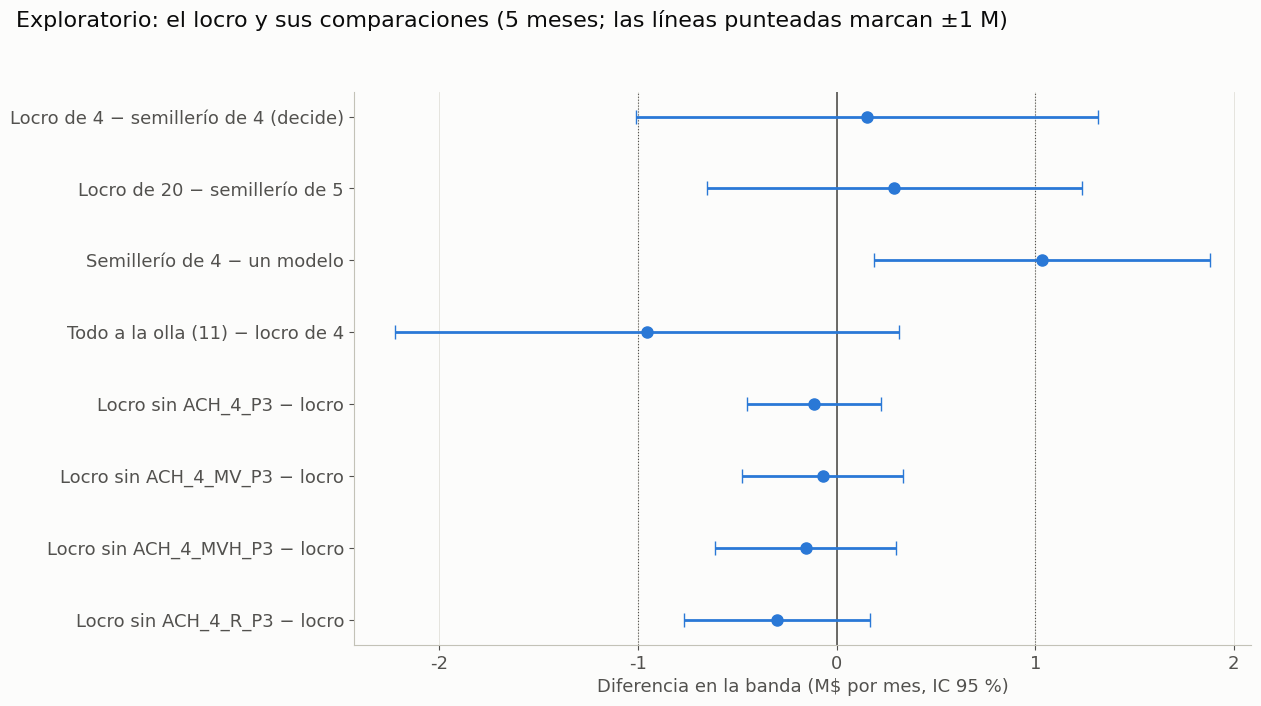

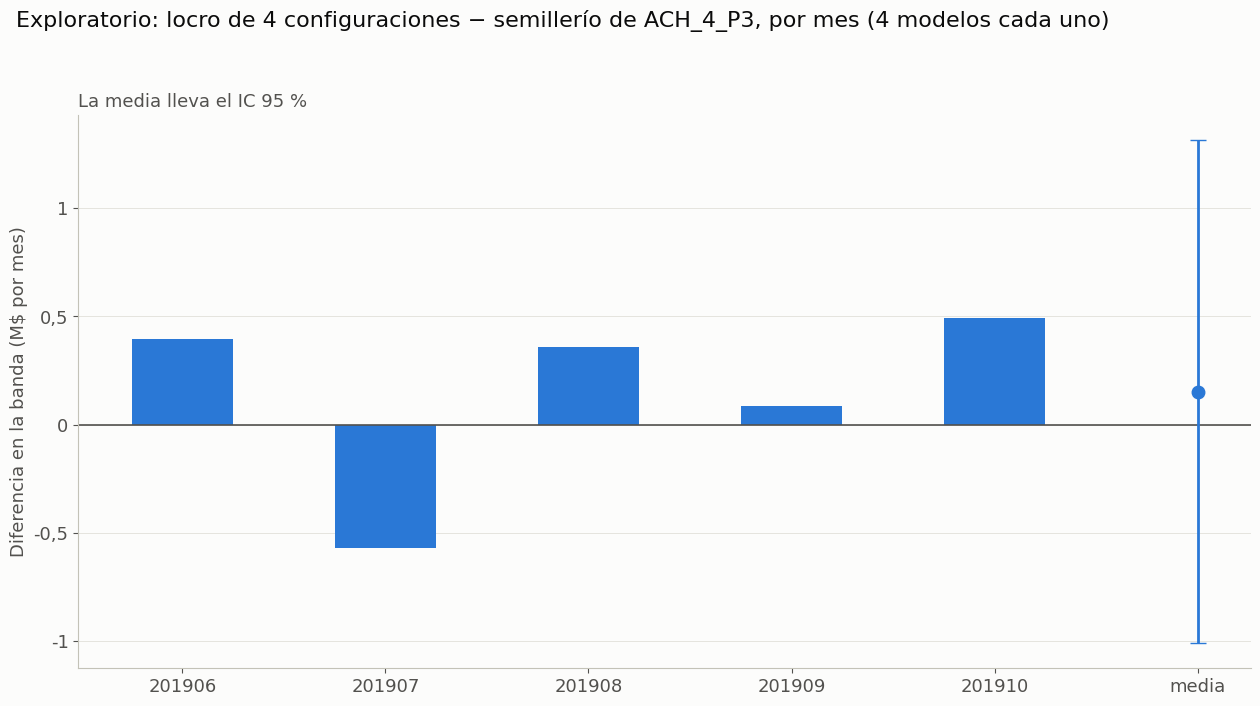

In [7]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


formato = FuncFormatter(lambda v, _: coma(v, 2).rstrip('0').rstrip(','))
NOMBRES = {'locro': 'Locro de 4 − semillerío de 4 (decide)', 'locro_20': 'Locro de 20 − semillerío de 5',
           'semillerio_4': 'Semillerío de 4 − un modelo', 'olla': 'Todo a la olla (11) − locro de 4',
           **{f'sin_{c}': f'Locro sin {c} − locro' for c in RECETA}}

fig, ax = plt.subplots(figsize=TAMANO)
r = comparacion.iloc[::-1].reset_index(drop=True)
y = np.arange(len(r))
ax.axvline(0, color=TINTA_2, lw=1.2)
for lado in (-UMBRAL, UMBRAL):
    ax.axvline(lado, color=TINTA_2, lw=0.8, ls=':')
ax.errorbar(r['d_M'], y, xerr=[r['d_M'] - r['ic95_inf_M'], r['ic95_sup_M'] - r['d_M']], fmt='o', color=AZUL, ms=8, capsize=5, lw=2)
ax.set_yticks(y, [NOMBRES[a] for a in r['a']])
ax.xaxis.set_major_formatter(formato)
ax.set_xlabel('Diferencia en la banda (M$ por mes, IC 95 %)')
ax.grid(axis='y', visible=False)
fig.suptitle('Exploratorio: el locro y sus comparaciones (5 meses; las líneas punteadas marcan ±1 M)', x=0.02, ha='left', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '21_1_locro.png', dpi=DPI)
plt.show()

r = comparacion.iloc[0]
fig, ax = plt.subplots(figsize=TAMANO)
ax.axhline(0, color=TINTA_2, lw=1.2)
x = [str(m) for m in MESES_EVALUADOS] + ['media']
ax.bar(x[:-1], [r[f'd_{m}'] for m in MESES_EVALUADOS], color=AZUL, width=0.5)
ax.errorbar([x[-1]], [r.d_M], yerr=[[r.d_M - r.ic95_inf_M], [r.ic95_sup_M - r.d_M]], fmt='o', color=AZUL, ms=9, capsize=6, lw=2)
ax.yaxis.set_major_formatter(formato)
ax.set_ylabel('Diferencia en la banda (M$ por mes)')
ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)
fig.suptitle('Exploratorio: locro de 4 configuraciones − semillerío de ACH_4_P3, por mes (4 modelos cada uno)',
             x=0.02, ha='left', fontsize=16)
ax.set_title('La media lleva el IC 95 %', loc='left', color=TINTA_2, fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '21_2_por_mes.png', dpi=DPI)
plt.show()

## 8. Lectura fijada antes de correr

Decide el locro de la receta contra el semillerío de `ACH_4_P3`, con 4 modelos cada uno. `d` es la diferencia media en la banda:

| `d` | Lectura |
|---|---|
| +1 M o más | Suma: el locro pasa a ser la vigente |
| Entre −1 y +1 M | Empate: queda `ACH_4_P3`, que es más simple |
| −1 M o menos | Resta: queda `ACH_4_P3` |

El intervalo se informa siempre. Los 5 meses ya se miraron para cada ingrediente; la receta se fijó por una propiedad de las configuraciones, no por este resultado.

**Control 7:** las salidas anteriores no cambiaron.

In [8]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 7
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()

lectura = lambda d: 'Suma' if d >= UMBRAL else ('Resta' if d <= -UMBRAL else 'Empate')
for r in comparacion.itertuples():
    marca = ' · DECIDE' if (r.a, r.b) == DECIDE else ''
    semillas = f' · semillas a favor {r.semillas_a_favor:.0f} de {N_SEMILLAS}' if r.semillas_a_favor == r.semillas_a_favor else ''
    print(f'{NOMBRES[r.a]}: {r.d_M:+.2f} M ({r.ic95_inf_M:.2f} a {r.ic95_sup_M:.2f}) · error {r.error_total_M:.2f} M'
          f'{semillas} · {lectura(r.d_M)}{marca}')

r = comparacion.iloc[0]
assert (r.a, r.b) == DECIDE
pd.DataFrame([{'config': 'locro', 'hipotesis': 'El locro de ' + ' + '.join(RECETA) + ' gana más que el semillerío de ACH_4_P3 con la misma cantidad de modelos',
               'contra': 'semillerio_4', 'modelos': MODELOS['locro'], 'd_M': round(r.d_M, 3), 'resultado': lectura(r.d_M),
               'decide': True}]).to_csv(RESULTADOS / '21_iteraciones.tsv', sep='\t', index=False)

Control de salidas OK · 0.4 min en total · memoria máxima 1.1 GB

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

Locro de 4 − semillerío de 4 (decide): +0.15 M (-1.01 a 1.32) · error 0.59 M · semillas a favor 3 de 5 · Empate · DECIDE
Locro de 20 − semillerío de 5: +0.29 M (-0.65 a 1.23) · error 0.48 M · Empate
Semillerío de 4 − un modelo: +1.04 M (0.19 a 1.88) · error 0.43 M · semillas a favor 5 de 5 · Suma
Todo a la olla (11) − locro de 4: -0.96 M (-2.23 a 0.31) · error 0.65 M · semillas a favor 0 de 5 · Empate
Locro sin ACH_4_P3 − locro: -0.11 M (-0.45 a 0.23) · error 0.17 M · semillas a favor 1 de 5 · Empate
Locro sin ACH_4_MV_P3 − locro: -0.07 M (-0.48 a 0.34) · error 0.21 M · semillas a favor 2 de 5 · Empate
Locro sin ACH_4_MVH_P3 − locro: -0.16 M (-0.61 a 0.30) · error 0.23 M · semillas a favor 1 de 5 · Empate
Locro sin ACH_4_R_P3 − locro: -0.30 M (-0.77 a 0.17) · error 0.24 M · semillas a favor 1 de 5 · Empate
